## 1. Logistic Regression: 2D Decision Boundary (Figure 4-24)

When using **two features** (Petal length and Petal width) instead of one, the decision boundary is no longer a single point — it becomes a **straight line** dividing the 2D plane.

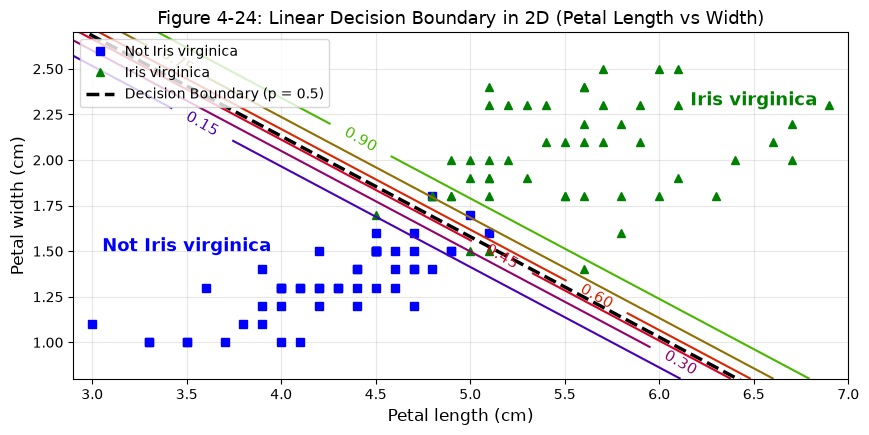

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.linear_model import LogisticRegression

# 1. Load Iris data (Petal length & Petal width)
iris = datasets.load_iris()
X = iris["data"][:, (2, 3)]  # petal length, petal width
y = (iris["target"] == 2).astype(int)  # 1 if Virginica, else 0 (using int instead of np.int)

# 2. Train Logistic Regression with high C (no regularization)
log_reg = LogisticRegression(solver="lbfgs", C=10**10, random_state=42)
log_reg.fit(X, y)

# 3. Create grid of points and compute probabilities
x0, x1 = np.meshgrid(
    np.linspace(2.9, 7, 500).reshape(-1, 1),
    np.linspace(0.8, 2.7, 200).reshape(-1, 1),
)
X_new = np.c_[x0.ravel(), x1.ravel()]
y_proba = log_reg.predict_proba(X_new)

# 4. Plot data points and decision boundary line
plt.figure(figsize=(10, 4.5))
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Not Iris virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "g^", label="Iris virginica")

zz = y_proba[:, 1].reshape(x0.shape)
contour = plt.contour(x0, x1, zz, cmap=plt.cm.brg)

# The decision boundary equation: theta_0 + theta_1 * x0 + theta_2 * x1 = 0
# Solving for x1: x1 = -(theta_1 * x0 + theta_0) / theta_2
left_right = np.array([2.9, 7])
boundary = -(log_reg.coef_[0][0] * left_right + log_reg.intercept_[0]) / log_reg.coef_[0][1]

plt.clabel(contour, inline=1, fontsize=11)
plt.plot(left_right, boundary, "k--", linewidth=2.5, label="Decision Boundary (p = 0.5)")
plt.text(3.5, 1.5, "Not Iris virginica", fontsize=13, color="b", ha="center", weight="bold")
plt.text(6.5, 2.3, "Iris virginica", fontsize=13, color="g", ha="center", weight="bold")
plt.xlabel("Petal length (cm)", fontsize=12)
plt.ylabel("Petal width (cm)", fontsize=12)
plt.axis([2.9, 7, 0.8, 2.7])
plt.legend(loc="upper left", fontsize=10)
plt.title("Figure 4-24: Linear Decision Boundary in 2D (Petal Length vs Width)", fontsize=13)
plt.grid(True, alpha=0.3)
plt.show()


**What's going on in Figure 4-24:**
* **The Boundary Equation**: The model classifies points based on $z = \theta_0 + \theta_1 x_0 + \theta_2 x_1$. At the $50\%$ boundary ($z = 0$), solving for $x_1$ gives the straight dashed line: $$x_1 = -\frac{\theta_1 x_0 + \theta_0}{\theta_2}$$
* **The Black Dashed Line**: The exact 50/50 line ($P = 0.5$). Above/right $\to$ *Iris virginica*; below/left $\to$ *Not Virginica*.
* **Contour Lines ($0.15$ to $0.90$)**: Probability slices showing model confidence rising smoothly as you move further from the line.

## 2. Softmax Regression: Multiclass Decision Boundaries (Figure 4-25)

Softmax Regression generalizes Logistic Regression to directly classify **multiple classes** (all 3 Iris species).

> **Key note:** Softmax is *multiclass* (picks the single class with the highest probability), not *multilabel* (it cannot predict multiple classes at once for the same flower).

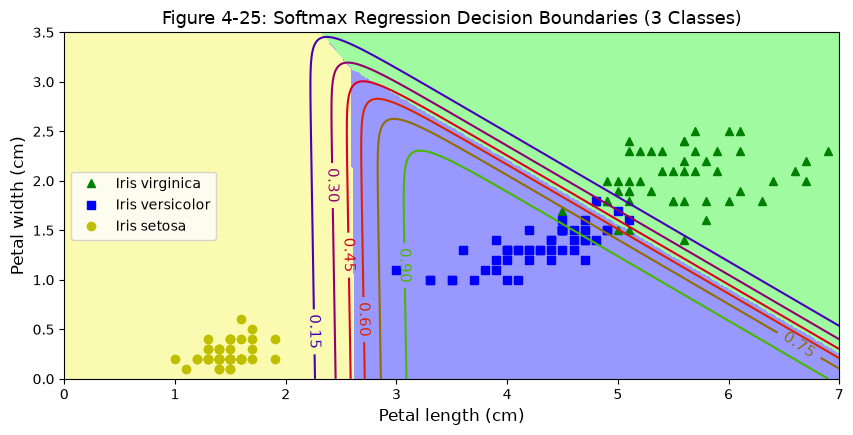

Prediction for [length=5cm, width=2cm]: class 2 (virginica)
Probabilities: Setosa = 0.000062%, Versicolor = 5.74%, Virginica = 94.26%


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.linear_model import LogisticRegression
from matplotlib.colors import ListedColormap

# 1. Load 2 features and all 3 classes (0: Setosa, 1: Versicolor, 2: Virginica)
iris = datasets.load_iris()
X = iris["data"][:, (2, 3)]  # petal length, petal width
y = iris["target"]

# 2. Train Softmax Regression
# Note: In scikit-learn 1.5+, multinomial is used automatically (multi_class argument is deprecated/removed)
softmax_reg = LogisticRegression(C=10, random_state=42)
softmax_reg.fit(X, y)

# 3. Compute grid predictions and probabilities
x0, x1 = np.meshgrid(
    np.linspace(0, 8, 500).reshape(-1, 1),
    np.linspace(0, 3.5, 200).reshape(-1, 1),
)
X_new = np.c_[x0.ravel(), x1.ravel()]

y_proba = softmax_reg.predict_proba(X_new)
y_predict = softmax_reg.predict(X_new)

zz1 = y_proba[:, 1].reshape(x0.shape)
zz = y_predict.reshape(x0.shape)

# 4. Plot 3-class decision boundaries
plt.figure(figsize=(10, 4.5))
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Iris virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Iris versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Iris setosa")

custom_cmap = ListedColormap(['#fafab0', '#9898ff', '#a0faa0'])
plt.contourf(x0, x1, zz, cmap=custom_cmap)
contour = plt.contour(x0, x1, zz1, cmap=plt.cm.brg)
plt.clabel(contour, inline=1, fontsize=11)
plt.xlabel("Petal length (cm)", fontsize=12)
plt.ylabel("Petal width (cm)", fontsize=12)
plt.legend(loc="center left", fontsize=10)
plt.axis([0, 7, 0, 3.5])
plt.title("Figure 4-25: Softmax Regression Decision Boundaries (3 Classes)", fontsize=13)
plt.show()

# 5. Prediction for a sample flower [5 cm length, 2 cm width]
pred = softmax_reg.predict([[5, 2]])[0]
proba = softmax_reg.predict_proba([[5, 2]])[0]
names = iris["target_names"]
print(f"Prediction for [length=5cm, width=2cm]: class {pred} ({names[pred]})")
print(f"Probabilities: Setosa = {proba[0]:.6%}, Versicolor = {proba[1]:.2%}, Virginica = {proba[2]:.2%}")


**What's going on in Figure 4-25:**
* **3 Colored Regions**: Yellow is *Setosa*, Blue/Purple is *Versicolor*, Green is *Virginica*. The model picks whichever region a point falls into.
* **Linear Decision Boundaries**: The borders between any two classes are **straight lines**. Notice all three boundary lines meet at a single central point.
* **Contour Lines**: Show the estimated probability of *Iris versicolor* (e.g., the curved line labeled $0.450$ is where $P(\text{versicolor}) = 45\%$).
* **Highest Score Wins**: A flower with $5$ cm length and $2$ cm width has a $94.3\%$ chance of Virginica, so the model confidently outputs **Virginica** (`class 2`).